In [7]:
!pip -q install kagglehub

In [8]:
from pathlib import Path
import pandas as pd
import kagglehub

dataset_dir = Path(
    kagglehub.dataset_download(
        "imakash3011/online-shoppers-purchasing-intention-dataset"
    )
)

print("Downloaded dataset folder:", dataset_dir)

# Search every CSV and select one whose column names include Revenue.
csv_files = list(dataset_dir.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files were found in {dataset_dir}. "
        "Check that the Kaggle download completed."
    )

def clean_column_name(name):
    return str(name).replace("\ufeff", "").strip()

matching_files = []

print("\nCSV files and their columns:")
for path in csv_files:
    preview = pd.read_csv(path, nrows=5)
    preview.columns = [clean_column_name(c) for c in preview.columns]
    print(f"\n{path.name}: {preview.columns.tolist()}")

    if any(c.casefold() == "revenue" for c in preview.columns):
        matching_files.append(path)

if not matching_files:
    raise ValueError(
        "The downloaded CSV files do not contain a Revenue column. "
        "Check the printed file names and columns: the selected Kaggle "
        "dataset may differ from Online Shoppers Purchasing Intention."
    )

csv_path = matching_files[0]
df = pd.read_csv(csv_path)
df.columns = [clean_column_name(c) for c in df.columns]

# Locate the actual capitalization used in the file.
target_name = next(c for c in df.columns if c.casefold() == "revenue")

print("\nSelected file:", csv_path.name)
print("Target column:", target_name)
print("Dataset shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'online-shoppers-purchasing-intention-dataset' dataset.
Downloaded dataset folder: /kaggle/input/online-shoppers-purchasing-intention-dataset

CSV files and their columns:

online_shoppers_intention.csv: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Selected file: online_shoppers_intention.csv
Target column: Revenue
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nPurchase outcome counts:")
print(df[target_name].value_counts(dropna=False))

Columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

Missing values per column:


,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Duplicate rows: 125

Purchase outcome counts:
Revenue
False    10422
True      1908
Name: count, dtype: int64


In [10]:
# Convert common text labels to True/False.
if df[target_name].dtype == "object":
    values = df[target_name].astype(str).str.strip().str.casefold()
    target_map = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "yes": True,
        "no": False,
    }
    converted = values.map(target_map)

    if converted.isna().any():
        print("Unrecognized Revenue values:", values[converted.isna()].unique())
        raise ValueError("Revenue contains values this notebook cannot interpret.")

    df[target_name] = converted

df = df.drop_duplicates().dropna(subset=[target_name]).copy()
df[target_name] = df[target_name].astype(bool)

print("Shape after removing duplicates and missing target rows:", df.shape)
print("\nPurchase counts:")
print(df[target_name].value_counts())

print("\nPurchase percentages:")
print((df[target_name].value_counts(normalize=True) * 100).round(2))

Shape after removing duplicates and missing target rows: (12205, 18)

Purchase counts:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Purchase percentages:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


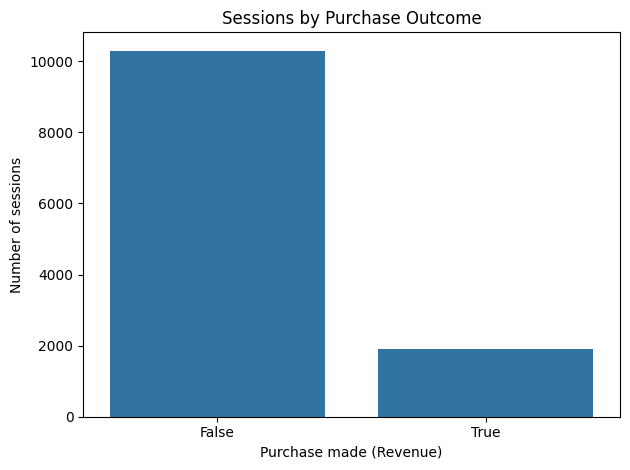

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x=target_name)
plt.title("Sessions by Purchase Outcome")
plt.xlabel("Purchase made (Revenue)")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

In [12]:
visitor_summary = (
    df.groupby("VisitorType", observed=True)[target_name]
      .agg(sessions="size", purchases="sum", purchase_rate="mean")
)

visitor_summary["purchase_rate_percent"] = (
    visitor_summary["purchase_rate"] * 100
).round(2)

display(visitor_summary)

,sessions,purchases,purchase_rate,purchase_rate_percent
VisitorType,,,,
New_Visitor,1693,422,0.249262,24.93
Other,81,16,0.197531,19.75
Returning_Visitor,10431,1470,0.140926,14.09


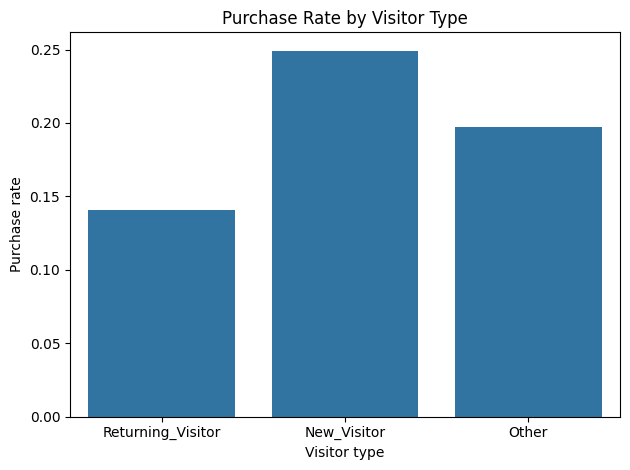

In [13]:
sns.barplot(data=df, x="VisitorType", y=target_name, errorbar=None)
plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor type")
plt.ylabel("Purchase rate")
plt.tight_layout()
plt.show()

In [14]:
weekend_summary = (
    df.groupby("Weekend", observed=True)[target_name]
      .agg(sessions="size", purchases="sum", purchase_rate="mean")
)

weekend_summary["purchase_rate_percent"] = (
    weekend_summary["purchase_rate"] * 100
).round(2)

display(weekend_summary)

,sessions,purchases,purchase_rate,purchase_rate_percent
Weekend,,,,
False,9346,1409,0.150760,15.08
True,2859,499,0.174537,17.45


,sessions,purchases,purchase_rate,purchase_rate_percent
ProductPagesGroup,,,,
0,38,6,0.157895,15.79
1,504,13,0.025794,2.58
2–5,1702,83,0.048766,4.88
6–10,1804,185,0.102550,10.25
11–20,2560,392,0.153125,15.31
21+,5597,1229,0.219582,21.96


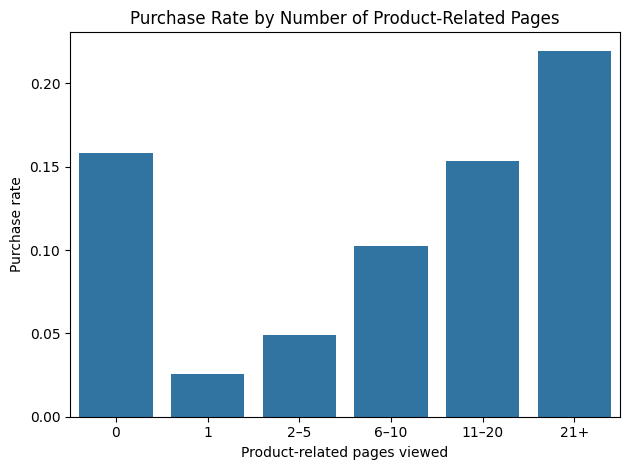

In [15]:
df["ProductPagesGroup"] = pd.cut(
    df["ProductRelated"],
    bins=[-1, 0, 1, 5, 10, 20, float("inf")],
    labels=["0", "1", "2–5", "6–10", "11–20", "21+"]
)

page_summary = (
    df.groupby("ProductPagesGroup", observed=True)[target_name]
      .agg(sessions="size", purchases="sum", purchase_rate="mean")
)

page_summary["purchase_rate_percent"] = (
    page_summary["purchase_rate"] * 100
).round(2)

display(page_summary)

sns.barplot(data=df, x="ProductPagesGroup", y=target_name, errorbar=None)
plt.title("Purchase Rate by Number of Product-Related Pages")
plt.xlabel("Product-related pages viewed")
plt.ylabel("Purchase rate")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X = df.drop(columns=[target_name, "PageValues", "ProductPagesGroup"], errors="ignore")
y = df[target_name].astype(bool)

X = pd.get_dummies(X, dtype=int)
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=3000, class_weight="balanced")
model.fit(X_train, y_train)

print(classification_report(y_test, model.predict(X_test), zero_division=0))

              precision    recall  f1-score   support

       False       0.92      0.62      0.74      2059
        True       0.25      0.69      0.37       382

    accuracy                           0.63      2441
   macro avg       0.59      0.66      0.56      2441
weighted avg       0.81      0.63      0.68      2441



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [18]:
from sklearn.metrics import confusion_matrix, roc_auc_score

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("Confusion matrix:\n", confusion_matrix(y_test, predictions))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))

Confusion matrix:
 [[1280  779]
 [ 117  265]]
ROC-AUC: 0.732
